In [5]:
%pip install pandas xgboost shap scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Final\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training XGBoost Model...
Accuracy: 0.78
AUROC Score: 0.87

Generating SHAP Explainability Plot...


PermutationExplainer explainer: 61it [00:21,  2.83it/s]                        


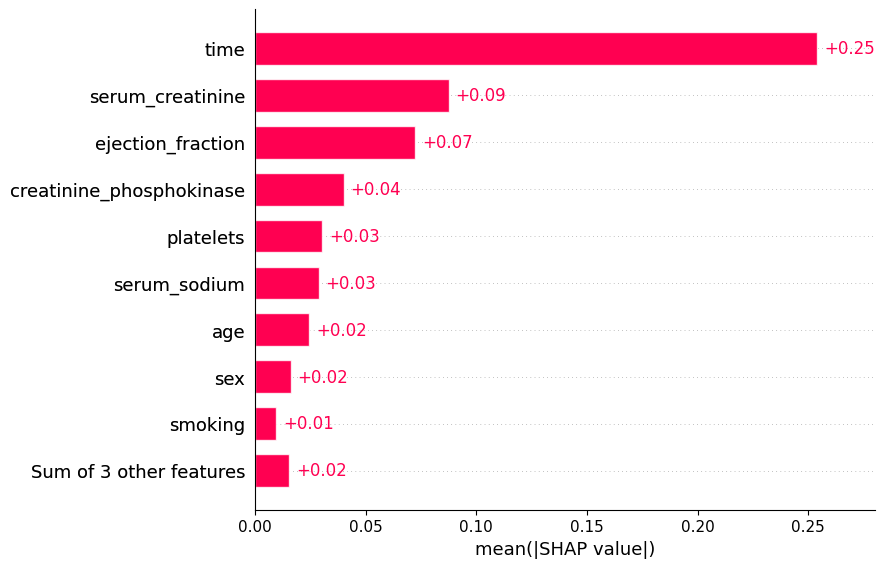

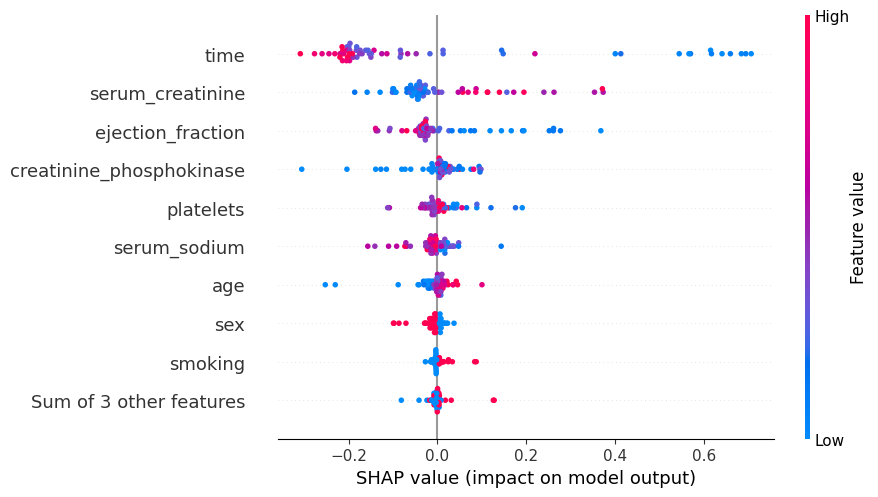

In [6]:
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
import warnings
warnings.filterwarnings('ignore') # Hides annoying red warning text

# 1. Load the dataset using your exact file path
# Notice the 'r' before the string. This tells Python to read the backslashes correctly!
# Try this path first (if you moved it into the data folder):
file_path = r"C:\Final\cardiac-arrest-prediction\heart_failure\Heart_failure_clinical_records_dataset.csv.csv"

# If it's still in the main folder, make sure the name is EXACTLY correct:
# file_path = r"C:\Final\cardiac-arrest-prediction\heart_failure_clinical_records_dataset.csv"

df = pd.read_csv(file_path)
df.head() # This will show the first 5 rows if successful

# 2. Separate the Features (Vitals/Labs) from the Target (Death Event)
X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

# 3. Split the data: 80% for training the AI, 20% for testing it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the XGBoost Model
print("Training XGBoost Model...")
model = xgb.XGBClassifier(eval_metric='logloss', random_state=42)
model.fit(X_train, y_train)

# 5. Test the Model's accuracy
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, predictions):.2f}")
print(f"AUROC Score: {roc_auc_score(y_test, probabilities):.2f}")

# 6. EXPLAINABLE AI: Use Permutation Explainer for maximum compatibility
print("\nGenerating SHAP Explainability Plot...")

# We pass the prediction function (predict_proba) instead of the model object
# This makes it version-independent
explainer = shap.Explainer(model.predict, X_train)
shap_values = explainer(X_test) # Use X_test here for a faster, cleaner plot

# 7. Visualize the results
# This creates a beautiful bar chart showing the most important features
shap.plots.bar(shap_values)

# Optional: Also show the beeswarm (the colorful dots)
plt.figure() # Creates a new figure so they don't overlap
shap.plots.beeswarm(shap_values)

In [7]:
import pickle

# Save the trained XGBoost model
with open('cardiac_model.pkl', 'wb') as f:
    pickle.dump(model, f)

print("Model saved successfully as cardiac_model.pkl")

Model saved successfully as cardiac_model.pkl
